# Assignment 08: Grouped Summaries of an Imaging Network

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import pyarrow

print("pandas:", pd.__version__)
print("pyarrow:", pyarrow.__version__)

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

MISSING_PATH = OUTPUT_DIR / "missing_by_modality.csv"
SITE_SUMMARY_PATH = OUTPUT_DIR / "site_summary.csv"
SITE_MODALITY_PATH = OUTPUT_DIR / "site_modality_summary.csv"
DELAYED_STAT_PATH = OUTPUT_DIR / "delayed_stat_exams.csv"
CT_DOSE_PATH = OUTPUT_DIR / "ct_dose_review.csv"
SLOWEST_PATH = OUTPUT_DIR / "slowest_stat_reports.csv"
PIVOT_PATH = OUTPUT_DIR / "median_report_pivot.csv"
PAIRPLOT_PNG = OUTPUT_DIR / "pairplot.png"  # seaborn route
PAIRPLOT_HTML = OUTPUT_DIR / "pairplot.html"  # Altair route: one of these two
PAIRPLOT_JSON = OUTPUT_DIR / "pairplot.json"

pandas: 3.0.5
pyarrow: 25.0.0


## Load the data

This cell downloads the exam log from the course repository when `data/` lacks it (`urlretrieve(url, path)` saves the file at a web address to `path`), then reads it: one row per exam. Run it as it is.

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/christopherseaman/datasci_217/main/08/assignment/data"
DATA_FILES = ["imaging_exams.parquet"]

DATA_DIR.mkdir(exist_ok=True)
for name in DATA_FILES:
    if not (DATA_DIR / name).exists():
        print("downloading", name)
        urlretrieve(f"{DATA_URL}/{name}", DATA_DIR / name)

exams = pd.read_parquet(DATA_DIR / "imaging_exams.parquet")
print("exams:", exams.shape)
exams.head()

exams: (540228, 15)


,exam_id,patient_id,site,exam_date,age,sex,setting,priority,modality,body_region,scan_min,dose_msv,wait_hr,report_hr,reader_id
0,E0000001,P077750,Northgate,2025-01-01,67,M,Inpatient,Routine,Ultrasound,Abdomen/Pelvis,28,NaN,43.3,11.12,T04
1,E0000002,P164273,Downtown,2025-01-01,75,M,Inpatient,Urgent,MRI,Extremity,51,NaN,9.0,1.75,T01
2,E0000003,P198046,Northgate,2025-01-01,70,M,Inpatient,STAT,CT,Head,12,2.188,2.6,2.11,T02
3,E0000004,P134356,Northgate,2025-01-01,50,F,ED,STAT,X-ray,Chest,7,0.023,0.5,NaN,T02
4,E0000005,P054587,Harbor,2025-01-01,7,M,ED,Urgent,X-ray,Spine,7,0.404,12.1,4.16,T02


## Task 1: Explore the log and summarize each site

### 1.1 Explore the exam log

> **Checkpoint: `output/pairplot.png`, or `output/pairplot.html` or `.json`**
> One pairplot of all five numeric columns, from seaborn or Altair.

> **Checkpoint: `output/missing_by_modality.csv`**
> Four rows, `CT` to `X-ray`, under the header `modality,report_hr,dose_msv`.

In [ ]:
distinct_exams = exams['exam_id'].nunique()  #  (README 1.1 step 1): distinct exam_id values
patients = exams['patient_id'].nunique()  #  (README 1.1 step 1): distinct patient_id values
print("rows:", len(exams))
print("distinct exams:", distinct_exams)
print("patients:", patients)

#  (README 1.1 step 2): info() and describe()
exams.info()
exams.describe()

rows: 540228
distinct exams: 540228
patients: 210000
<class 'pandas.DataFrame'>
RangeIndex: 540228 entries, 0 to 540227
Data columns (total 15 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   exam_id      540228 non-null  str           
 1   patient_id   540228 non-null  str           
 2   site         540228 non-null  str           
 3   exam_date    540228 non-null  datetime64[ms]
 4   age          540228 non-null  int64         
 5   sex          540228 non-null  str           
 6   setting      540228 non-null  str           
 7   priority     540228 non-null  str           
 8   modality     540228 non-null  str           
 9   body_region  540228 non-null  str           
 10  scan_min     540228 non-null  int64         
 11  dose_msv     347619 non-null  float64       
 12  wait_hr      540228 non-null  float64       
 13  report_hr    537966 non-null  float64       
 14  reader_id    540228 non-null  str         

,exam_date,age,scan_min,dose_msv,wait_hr,report_hr
count,540228,540228.000000,540228.000000,347619.000000,540228.000000,537966.000000
mean,2025-07-01 00:51:55.804000,56.140002,17.933854,2.522546,82.990732,9.562691
min,2025-01-01 00:00:00,1.000000,2.000000,0.000000,0.100000,0.050000
25%,2025-03-29 00:00:00,45.000000,8.000000,0.013000,1.500000,0.990000
50%,2025-06-30 00:00:00,58.000000,12.000000,0.031000,19.600000,5.640000
75%,2025-10-03 00:00:00,71.000000,24.000000,2.584000,96.100000,13.100000
max,2025-12-31 00:00:00,97.000000,153.000000,46.512000,4058.200000,252.500000
std,NaN,21.466531,13.426752,4.351553,156.082523,11.984275


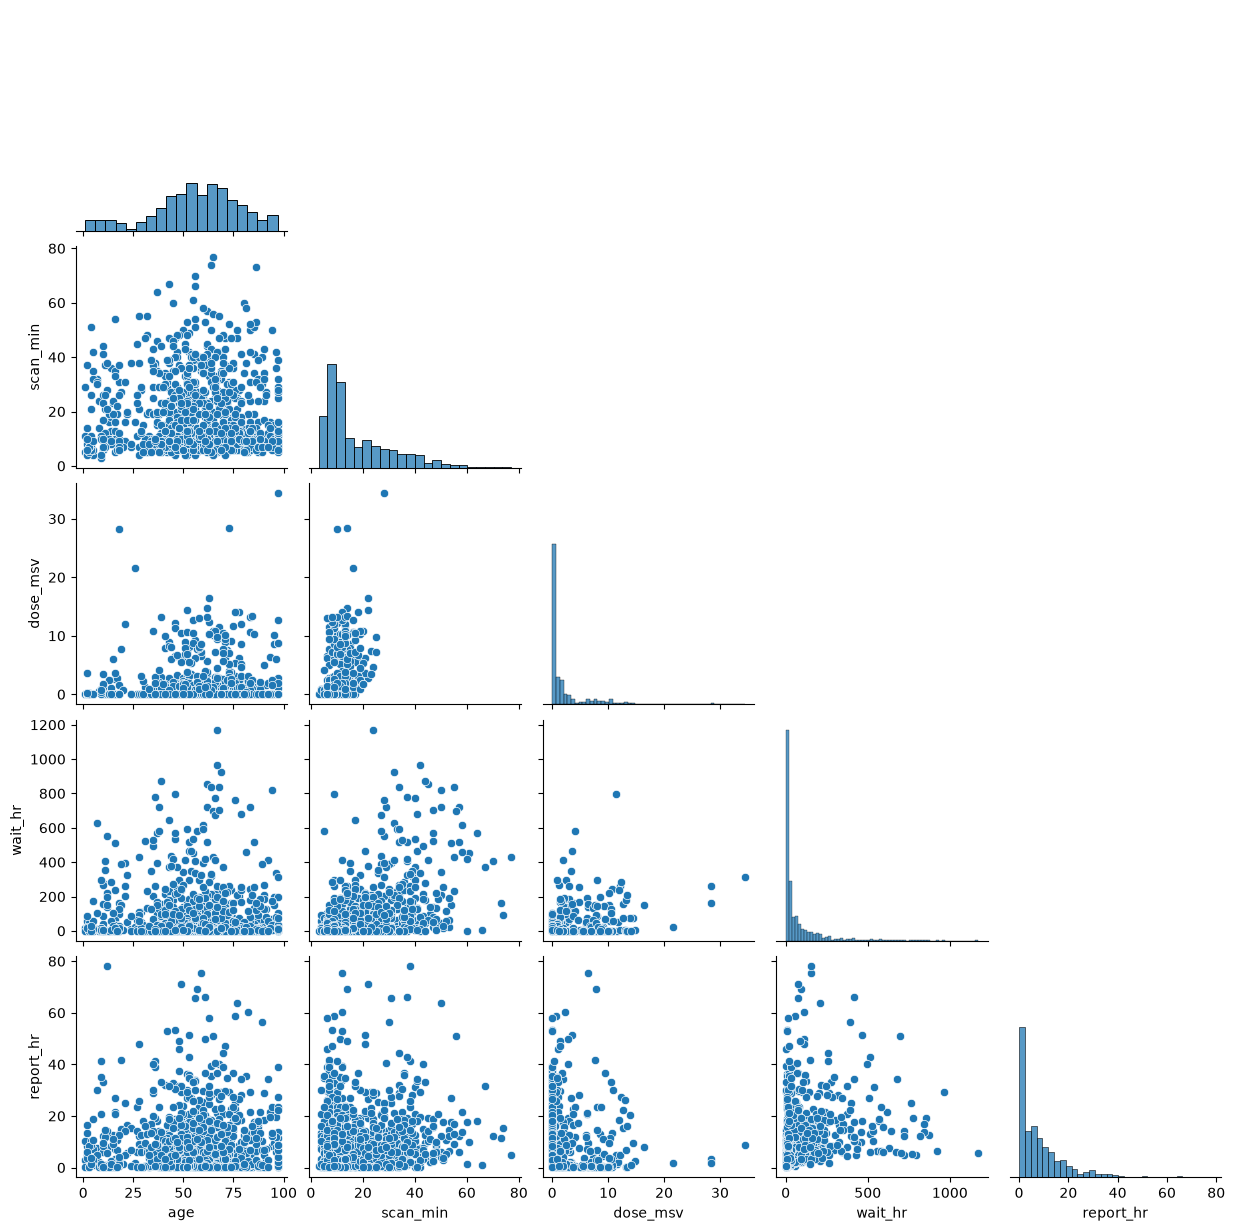

In [ ]:
pairplot_columns = ["age", "scan_min", "dose_msv", "wait_hr", "report_hr"]  #  (README 1.1 step 3): the five numeric columns
pairplot_sample = exams[pairplot_columns].sample(n=1000, random_state=123)  #  (README 1.1 step 3): those columns for a random sample of 1,000 exams

#  (README 1.1 step 3): pick one route and delete the other
# seaborn: import seaborn as sns, draw the pairplot, and save it to PAIRPLOT_PNG
import seaborn as sns
grid = sns.pairplot(pairplot_sample, corner=True)
grid.savefig(PAIRPLOT_PNG)

In [ ]:
missing_by_modality = (
    exams.groupby("modality")[["report_hr", "dose_msv"]]
    .agg(lambda x: x.isna().mean())
)  #  (README 1.1 step 4): share of exams with no report_hr and no dose_msv, by modality
display(missing_by_modality)

#  (README 1.1 step 5): save missing_by_modality to MISSING_PATH, keeping its modality index
missing_by_modality.to_csv(MISSING_PATH, index=True)

q1, q3 = exams["wait_hr"].quantile([0.25, 0.75])  # (README 1.1 step 6): quartiles of wait_hr
upper = q3 + 1.5 * (q3 - q1)  # (README 1.1 step 6): the IQR upper fence
above_fence = exams["wait_hr"].gt(upper).sum()  # (README 1.1 step 6): how many waits are above it
print("quartiles:", q1, q3)
print("upper fence:", upper)
print("waits above the fence:", above_fence)

,report_hr,dose_msv
modality,,
CT,0.003868,0.0
MRI,0.005355,1.0
Ultrasound,0.004148,1.0
X-ray,0.003993,0.0


quartiles: 1.5 96.1
upper fence: 237.99999999999997
waits above the fence: 55401


### 1.2 Put the sites in reporting order

This step saves nothing.

In [ ]:
SITE_ORDER = ["Downtown", "Harbor", "Northgate", "Lakeside", "Hillcrest", "Riverside", "Westfield", "Valley", "Eastport"]  # Eastport opens in 2026

#  (README 1.2 step 1): overwrite exams["site"] with an ordered categorical in SITE_ORDER
exams["site"] = pd.Categorical(exams["site"], categories=SITE_ORDER, ordered=True)

print("site dtype:", exams["site"].dtype)

exams_per_site = exams.groupby("site", observed=False, dropna=False)["exam_id"].count()  #  (README 1.2 step 2): exams per site, keeping Eastport
exams_per_site

site dtype: category


site
Downtown     129876
Harbor       108818
Northgate    120961
Lakeside      44420
Hillcrest     37883
Riverside     35660
Westfield     37226
Valley        25384
Eastport          0
Name: exam_id, dtype: int64

### 1.3 Count exams, reports, and patients, and total the scanner time

> **Checkpoint: `output/site_summary.csv`**
> Eight rows under the header `site,exam_count,report_count,patient_count,total_scan_min,mean_scan_min`.

In [ ]:
site_summary = exams.groupby("site", observed=True, as_index=False).agg(
    exam_count = ("exam_id", "size"),
    report_count = ("report_hr", "count"),
    patient_count = ("patient_id", "nunique"),
    total_scan_min = ("scan_min", "sum"),
    mean_scan_min = ("scan_min", "mean")
)  #  (README 1.3 step 1): one groupby on site with five named aggregations

print("rows:", len(site_summary))

#  (README 1.3 step 2): save site_summary to SITE_SUMMARY_PATH
site_summary.to_csv(SITE_SUMMARY_PATH, index=False)  

site_summary

rows: 8


,site,exam_count,report_count,patient_count,total_scan_min,mean_scan_min
0,Downtown,129876,129366,60995,2239524,17.243555
1,Harbor,108818,108422,52764,1839569,16.905007
2,Northgate,120961,120484,61314,1999568,16.530683
3,Lakeside,44420,44206,26507,906052,20.397389
4,Hillcrest,37883,37689,22516,767578,20.261806
5,Riverside,35660,35487,21898,732561,20.542933
6,Westfield,37226,37032,23363,844368,22.682211
7,Valley,25384,25280,12905,359150,14.148676


## Task 2: Compare sites, modalities, and single exams

### 2.1 Summarize each site and modality

> **Checkpoint: `output/site_modality_summary.csv`**
> 31 rows under the header `site,modality,exam_count,median_wait_hr,median_report_hr`.

In [ ]:
site_modality = exams.groupby(["site", "modality"], observed=True, as_index=False).agg(
    exam_count = ("exam_id", "size"),
    median_wait_hr = ("wait_hr", "median"),
    median_report_hr = ("report_hr", "median")
)  #  (README 2.1 step 1): group by site and modality with three named aggregations

print("rows:", len(site_modality))

#  (README 2.1 step 2): save site_modality to SITE_MODALITY_PATH
site_modality.to_csv(SITE_MODALITY_PATH, index=False)

site_modality

rows: 31


,site,modality,exam_count,median_wait_hr,median_report_hr
0,Downtown,CT,33864,2.40,1.610
1,Downtown,MRI,15687,269.00,13.190
2,Downtown,Ultrasound,26678,56.70,5.940
3,Downtown,X-ray,53647,5.50,3.080
4,Harbor,CT,29776,2.20,1.140
5,Harbor,MRI,12326,278.30,9.820
6,Harbor,Ultrasound,21573,51.20,4.250
7,Harbor,X-ray,45143,4.50,2.020
8,Northgate,CT,34188,1.60,1.110
9,Northgate,MRI,12900,227.50,10.865


### 2.2 Flag STAT exams that waited far longer than their peers

> **Checkpoint: `output/delayed_stat_exams.csv`**
> 190 rows under the header `exam_id,site,modality,wait_hr,peer_median_wait_hr,wait_vs_peer_hr`.

In [ ]:
stat = exams[exams["priority"] == "STAT"].copy()  #  (README 2.2 step 1): the STAT exams, as a copy
#  (README 2.2 step 2): add peer_median_wait_hr with transform
stat["peer_median_wait_hr"] = stat.groupby(["site", "modality"])["wait_hr"].transform("median")  #  (README 2.2 step 2): add peer_median_wait_hr with transform
#  (README 2.2 step 3): add wait_vs_peer_hr
stat['wait_vs_peer_hr'] = stat['wait_hr'] - stat['peer_median_wait_hr']
print("STAT exams:", len(stat))

#  (README 2.2 step 4): STAT exams that waited over 8 hours, six columns
delayed_stat = stat[stat["wait_hr"] > 8][
    ["exam_id", "site", "modality", "wait_hr",
     "peer_median_wait_hr", "wait_vs_peer_hr"]
]  

print("delayed:", len(delayed_stat))

#  (README 2.2 step 5): save delayed_stat to DELAYED_STAT_PATH
delayed_stat.to_csv(DELAYED_STAT_PATH, index=False)

delayed_stat.sort_values("wait_hr", ascending=False).head(10)

STAT exams: 152925
delayed: 190


,exam_id,patient_id,site,exam_date,age,sex,setting,priority,modality,body_region,scan_min,dose_msv,wait_hr,report_hr,reader_id,peer_median_wait_hr,wait_vs_peer_hr
136396,E0136397,P057376,Lakeside,2025-03-31,86,F,Outpatient,STAT,MRI,Head,55,NaN,26.8,0.89,R27,1.4,25.4
336691,E0336692,P049572,Downtown,2025-08-16,69,M,ED,STAT,Ultrasound,Abdomen/Pelvis,21,NaN,24.4,1.24,R08,1.0,23.4
421348,E0421349,P051040,Downtown,2025-10-14,48,F,ED,STAT,Ultrasound,Abdomen/Pelvis,22,NaN,23.0,0.60,R03,1.0,22.0
287501,E0287502,P117784,Harbor,2025-07-13,1,M,ED,STAT,MRI,Head,37,NaN,21.5,0.53,R13,1.7,19.8
497437,E0497438,P189995,Harbor,2025-12-03,63,F,ED,STAT,MRI,Extremity,25,NaN,19.7,0.87,R10,1.7,18.0
452511,E0452512,P034734,Northgate,2025-11-04,69,M,Inpatient,STAT,MRI,Head,42,NaN,18.2,0.29,R16,1.6,16.6
543,E0000544,P119104,Downtown,2025-01-01,93,F,Inpatient,STAT,MRI,Head,48,NaN,17.4,1.35,R02,1.7,15.7
308054,E0308055,P019165,Valley,2025-07-28,63,F,ED,STAT,Ultrasound,Neck,16,NaN,16.5,0.28,R31,1.0,15.5
87969,E0087970,P145620,Harbor,2025-02-26,73,F,ED,STAT,MRI,Head,62,NaN,16.4,0.84,R14,1.7,14.7
447343,E0447344,P080529,Northgate,2025-10-31,71,F,ED,STAT,MRI,Head,28,NaN,15.8,0.70,R16,1.6,14.2


### 2.3 Build a CT radiation-dose review list

> **Checkpoint: `output/ct_dose_review.csv`**
> 1,253 rows under the header `exam_id,patient_id,dose_msv`.

In [ ]:
ct = exams[exams["modality"] == "CT"].copy()  #  (README 2.3 step 1): the CT exams

dose_review = ct.groupby("patient_id").filter(lambda x: x["dose_msv"].sum() >= 100)  #  (README 2.3 step 2): every CT of each patient whose doses add up to 100 mSv or more, with filter
print("rows:", len(dose_review))
print("patients:", dose_review["patient_id"].nunique())

row_mask = ct[ct["dose_msv"] >= 100]  #  (README 2.3 step 3): the row mask that tests each scan instead
print("row mask rows:", len(row_mask))

fast_review = ct[ct.groupby("patient_id")["dose_msv"].transform("sum") >= 100]  #  (README 2.3 step 4): the same rows from a transform mask

print("same rows as filter:", fast_review.equals(dose_review))

#  (README 2.3 step 5): save exam_id, patient_id, and dose_msv to CT_DOSE_PATH
dose_review[["exam_id", "patient_id", "dose_msv"]].to_csv(CT_DOSE_PATH, index=False)

dose_review.head()

rows: 1253
patients: 159
row mask rows: 0
same rows as filter: True


,exam_id,patient_id,site,exam_date,age,sex,setting,priority,modality,body_region,scan_min,dose_msv,wait_hr,report_hr,reader_id
13,E0000014,P202445,Northgate,2025-01-01,82,M,ED,STAT,CT,Head,11,1.981,1.1,0.34,T04
138,E0000139,P010342,Downtown,2025-01-01,97,M,Outpatient,Routine,CT,Chest/Abdomen/Pelvis,24,16.323,69.6,26.65,R06
1117,E0001118,P152807,Downtown,2025-01-02,75,F,ED,STAT,CT,Chest,12,6.509,0.6,0.56,R01
1213,E0001214,P097874,Harbor,2025-01-02,63,F,Outpatient,Routine,CT,Chest/Abdomen/Pelvis,32,19.777,132.3,17.64,R12
1399,E0001400,P074625,Lakeside,2025-01-02,80,F,Outpatient,Routine,CT,Chest/Abdomen/Pelvis,20,13.963,132.9,7.79,R27


### 2.4 Pull each site's three slowest STAT reports

> **Checkpoint: `output/slowest_stat_reports.csv`**
> 24 rows under the header `exam_id,site,modality,report_hr`.

In [ ]:
slowest = stat.groupby("site").apply(lambda x: x.nlargest(3, "report_hr"), include_groups=False)  #  (README 2.4 step 1): each site's three slowest STAT reports, with apply

print("rows:", len(slowest))
print("index levels:", slowest.index.nlevels)

#  (README 2.4 step 2): move the index levels back into columns and keep four columns
slowest = slowest.reset_index()[["exam_id", "site", "modality", "report_hr"]]


#  (README 2.4 step 3): save slowest to SLOWEST_PATH
slowest.to_csv(SLOWEST_PATH, index=False)

slowest


rows: 24
index levels: 2


,exam_id,site,modality,report_hr
0,E0313443,Downtown,X-ray,14.82
1,E0183831,Downtown,MRI,14.27
2,E0046635,Downtown,X-ray,12.49
3,E0180229,Harbor,X-ray,7.33
4,E0015432,Harbor,CT,7.00
5,E0060006,Harbor,X-ray,6.89
6,E0082383,Northgate,X-ray,8.34
7,E0404764,Northgate,MRI,8.22
8,E0506694,Northgate,MRI,7.50
9,E0427197,Lakeside,MRI,5.70


## Task 3: Pivot the report times

### 3.1 Build the pivot table and check it

> **Checkpoint: `output/median_report_pivot.csv`**
> Eight rows, `Downtown` to `Valley`, under the header `site,CT,MRI,Ultrasound,X-ray`; Valley's `MRI` cell stays empty.

In [ ]:
report_pivot = pd.pivot_table(exams, values="report_hr", index="site", columns="modality", aggfunc="median", observed = True)  #  (README 3.1 step 1): pivot table of median report_hr, sites as rows, modalities as columns
groupby_twin = exams.groupby(["site", "modality"])["report_hr"].median().unstack("modality")  #  (README 3.1 step 2): the same medians from a two-key groupby, unstacked
print("pivot matches its groupby twin:", report_pivot.equals(groupby_twin))
print("empty cells:", report_pivot.isna().sum().sum())

#  (README 3.1 step 3): save report_pivot to PIVOT_PATH, keeping its site index
report_pivot.to_csv(PIVOT_PATH, index=True)
report_pivot

pivot matches its groupby twin: True
empty cells: 1


modality,CT,MRI,Ultrasound,X-ray
site,,,,
Downtown,1.610,13.190,5.94,3.08
Harbor,1.140,9.820,4.25,2.02
Northgate,1.110,10.865,4.24,1.88
Lakeside,10.710,14.570,9.29,8.19
Hillcrest,10.685,14.605,9.59,8.38
Riverside,11.125,14.750,9.40,8.36
Westfield,10.750,14.580,9.30,8.42
Valley,2.020,NaN,7.12,4.56


### 3.2 Count the exams in each pair

This step saves nothing.

In [ ]:
exam_counts = pd.crosstab(exams["site"], exams["modality"])  #  (README 3.2): crosstab of exams by site and modality
exam_counts

modality,CT,MRI,Ultrasound,X-ray
site,,,,
Downtown,33864,15687,26678,53647
Harbor,29776,12326,21573,45143
Northgate,34188,12900,23444,50429
Lakeside,6744,9010,11504,17162
Hillcrest,5812,7704,9655,14712
Riverside,5576,7179,9231,13674
Westfield,5034,10644,8665,12883
Valley,6992,0,6409,11983


## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [ ]:
from check_assignment import run_checks

_ = run_checks()